# Módulo 1 — Práctica Día 2: NumPy, Xarray, Pandas y Matplotlib

Ejercicios de la práctica del **Día 2** (ver [`README.md`](../README.md)).

## Datos de partida

Usamos los mismos archivos reales de SENAMHI del Día 1. Hoy los leemos con
**Pandas**, con la función `leer_senamhi()` de abajo. Cómo funciona por
dentro se ve paso a paso en el **Ejercicio 4b**.

In [1]:
import numpy as np
import pandas as pd

CARPETA = "../../../data/senamhi/"
archivos = {
    "San Martín de Porres": "112265_2025_03.csv",
    "Campo de Marte":       "112181_2025_03.csv",
    "Von Humboldt":         "472AC278_2025_03.csv",
    "Ceres":                "112278_2025_03.csv",
    "Ñaña":                 "111290_2025_03.csv",
}


def leer_senamhi(archivo, columna="Temperatura (°C)"):
    """Serie horaria (hora local) de una columna de un CSV de SENAMHI."""
    d = pd.read_csv(CARPETA + archivo, sep=";", dtype=str)
    if columna not in d.columns:                   # Ceres no mide humedad
        return pd.Series(dtype=float)
    fechas = pd.to_datetime(d["Año"] + "-" + d["Mes"] + "-" + d["Día"] + " " + d["Hora"])
    valores = pd.to_numeric(d[columna], errors="coerce")   # "S/D" (sin dato) -> NaN
    return pd.Series(valores.values, index=fechas, name=columna)


leer_senamhi("472AC278_2025_03.csv").head()

2025-03-01 00:00:00    22.3
2025-03-01 01:00:00    21.4
2025-03-01 02:00:00    21.1
2025-03-01 03:00:00    20.8
2025-03-01 04:00:00    20.6
Name: Temperatura (°C), dtype: float64

## Ejercicio 1 — De bucles a NumPy (30 min)

Reescribimos el Ejercicio 1 del Día 1 (promedio, máximo, mínimo, conteo
sobre umbral) usando arreglos NumPy.

In [2]:
temperaturas_horarias = leer_senamhi("472AC278_2025_03.csv").loc["2025-03-14"].values
print("Von Humboldt, 14/03/2025 — temperaturas horarias (°C):", temperaturas_horarias)
print("Tipo:", type(temperaturas_horarias))   # .values entrega un arreglo de NumPy

Von Humboldt, 14/03/2025 — temperaturas horarias (°C): [21.7 21.5 21.3 20.9 20.6 20.3 20.3 20.5 21.7 23.8 26.1 27.6 27.9 27.8
 28.3 29.1 26.8 26.  24.5 22.6 22.4 22.2 21.9 21.4]
Tipo: <class 'numpy.ndarray'>


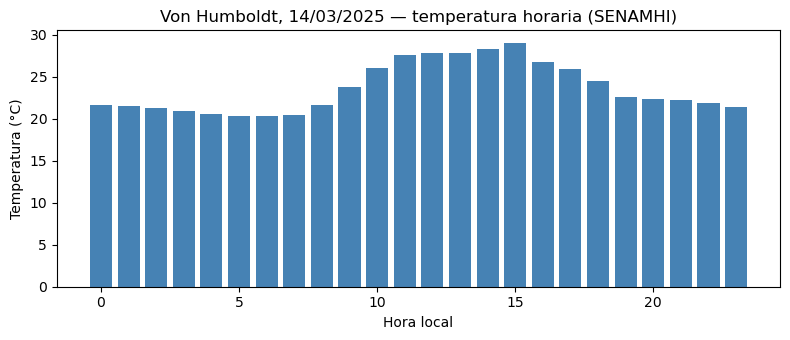

In [3]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(range(24), temperaturas_horarias, color="steelblue")
ax.set_xlabel("Hora local")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Von Humboldt, 14/03/2025 — temperatura horaria (SENAMHI)")
fig.tight_layout()
plt.show()

In [4]:
def resumen_temperaturas_np(valores, umbral=26.0):
    return {
        "promedio": round(float(valores.mean()), 2),
        "maximo": float(valores.max()),
        "minimo": float(valores.min()),
        "horas_sobre_umbral": int((valores > umbral).sum()),
    }

resumen_np = resumen_temperaturas_np(temperaturas_horarias)
print(resumen_np)
print()
print("Debe coincidir con el resultado del Día 1 (mismos datos).")
print("Comparación de código: la versión NumPy no necesita bucle ni",
      "acumuladores manuales (suma, maximo, minimo) — cada operación",
      "de reducción ya sabe recorrer todo el arreglo.")

{'promedio': 23.63, 'maximo': 29.1, 'minimo': 20.3, 'horas_sobre_umbral': 7}

Debe coincidir con el resultado del Día 1 (mismos datos).
Comparación de código: la versión NumPy no necesita bucle ni acumuladores manuales (suma, maximo, minimo) — cada operación de reducción ya sabe recorrer todo el arreglo.


## Ejercicio 2 — Broadcasting con sentido físico (30 min)

Grilla **inventada** `(niveles=5, lat=10, lon=10)` + perfil de corrección
vertical `(5,)`. Todavía no leemos una salida del WRF (eso es el Módulo 4):
aquí solo importa la forma de los arreglos.

In [5]:
niveles, lat, lon = 5, 10, 10
temperatura_base = 288.0
np.random.seed(10)
grilla = temperatura_base + np.random.normal(0, 0.3, size=(niveles, lat, lon))

correccion_vertical = np.array([0.0, -2.0, -4.0, -6.0, -8.0])  # (niveles,)

grilla_corregida = grilla + correccion_vertical[:, np.newaxis, np.newaxis]

# Verificación manual en un punto específico
i_nivel, i_lat, i_lon = 3, 5, 7
manual = grilla[i_nivel, i_lat, i_lon] + correccion_vertical[i_nivel]
broadcast = grilla_corregida[i_nivel, i_lat, i_lon]

print(f"Valor manual    en (nivel={i_nivel}, lat={i_lat}, lon={i_lon}): {manual:.4f}")
print(f"Valor broadcast en (nivel={i_nivel}, lat={i_lat}, lon={i_lon}): {broadcast:.4f}")
print("¿Coinciden? ->", np.isclose(manual, broadcast))

Valor manual    en (nivel=3, lat=5, lon=7): 282.4192
Valor broadcast en (nivel=3, lat=5, lon=7): 282.4192
¿Coinciden? -> True


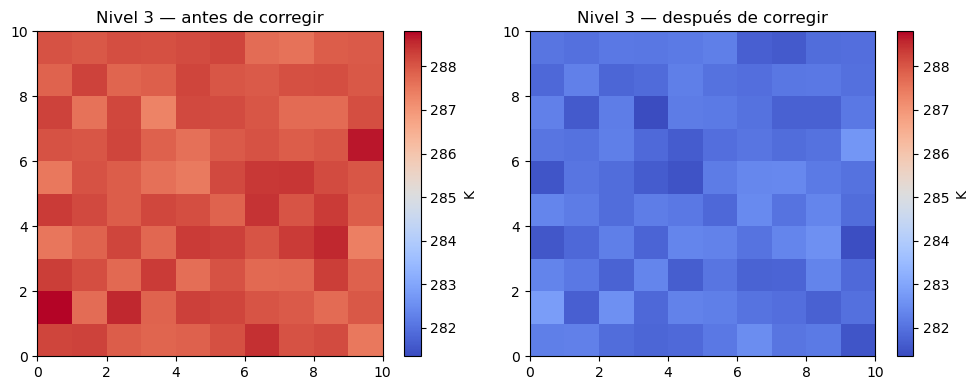

In [6]:
vmin = min(grilla[i_nivel].min(), grilla_corregida[i_nivel].min())
vmax = max(grilla[i_nivel].max(), grilla_corregida[i_nivel].max())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
im0 = axes[0].pcolormesh(grilla[i_nivel], cmap="coolwarm", vmin=vmin, vmax=vmax)
axes[0].set_title(f"Nivel {i_nivel} — antes de corregir")
plt.colorbar(im0, ax=axes[0], label="K")
im1 = axes[1].pcolormesh(grilla_corregida[i_nivel], cmap="coolwarm", vmin=vmin, vmax=vmax)
axes[1].set_title(f"Nivel {i_nivel} — después de corregir")
plt.colorbar(im1, ax=axes[1], label="K")
fig.tight_layout()
plt.show()

## Ejercicio 3 — Primer `DataArray` y `Dataset` desde cero (45 min)

`Dataset` con datos reales de las 5 estaciones × 72 horas (14 al 16 de marzo
de 2025): temperatura y humedad relativa, con selección por nombre y por
posición.

In [7]:
import xarray as xr

estaciones = list(archivos)
tiempo = pd.date_range("2025-03-14", periods=72, freq="h")   # hora local

# .reindex(tiempo): deja solo esas 72 horas; si falta alguna, pone NaN
temp = np.column_stack([leer_senamhi(a).reindex(tiempo) for a in archivos.values()])
humedad = np.column_stack([leer_senamhi(a, "Humedad (%)").reindex(tiempo) for a in archivos.values()])

ds = xr.Dataset(
    data_vars={
        "temperatura": (["tiempo", "estacion"], temp, {"units": "degC"}),
        "humedad": (["tiempo", "estacion"], humedad, {"units": "%"}),
    },
    coords={"tiempo": tiempo, "estacion": estaciones},
    attrs={"source": "SENAMHI, estaciones automáticas"},
)
ds

<xarray.Dataset> Size: 7kB
Dimensions:      (tiempo: 72, estacion: 5)
Coordinates:
  * tiempo       (tiempo) datetime64[us] 576B 2025-03-14 ... 2025-03-16T23:00:00
  * estacion     (estacion) <U20 400B 'San Martín de Porres' ... 'Ñaña'
Data variables:
    temperatura  (tiempo, estacion) float64 3kB 21.1 20.8 21.7 ... 20.9 22.0
    humedad      (tiempo, estacion) float64 3kB 100.0 90.0 83.0 ... nan 75.0
Attributes:
    source:   SENAMHI, estaciones automáticas

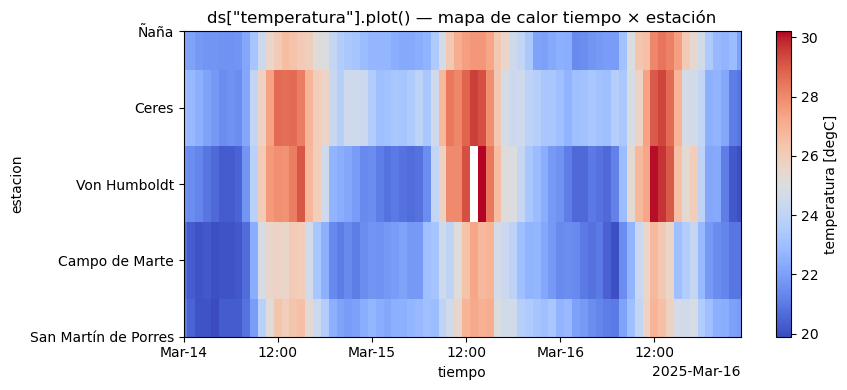

In [8]:
# ds["temperatura"].plot() sobre un DataArray 2D (tiempo x estacion) sin
# dimension espacial real dibuja un mapa de calor tiempo-estacion
fig, ax = plt.subplots(figsize=(9, 4))
ds["temperatura"].plot(x="tiempo", y="estacion", ax=ax, cmap="coolwarm")
ax.set_title('ds["temperatura"].plot() — mapa de calor tiempo × estación')
fig.tight_layout()
plt.show()

In [9]:
# Selección por nombre
temp_vh = ds["temperatura"].sel(estacion="Von Humboldt")

# Selección por posición (Von Humboldt es el índice 2)
temp_vh_pos = ds["temperatura"].isel(estacion=2)

# .equals() compara todo, y considera iguales dos NaN (el 15/03 falta una hora)
print("¿.sel y .isel devuelven lo mismo para Von Humboldt? ->", temp_vh.equals(temp_vh_pos))

print()
print("Promedio de temperatura por estación (NaN se ignora):")
print(ds["temperatura"].mean(dim="tiempo").to_pandas().round(2))

print()
print("Promedio de temperatura por hora (promedio espacial):")
print(ds["temperatura"].mean(dim="estacion").to_pandas().round(2).head())

¿.sel y .isel devuelven lo mismo para Von Humboldt? -> True

Promedio de temperatura por estación (NaN se ignora):
estacion
San Martín de Porres    23.31
Campo de Marte          22.79
Von Humboldt            23.75
Ceres                   24.69
Ñaña                    24.01
Name: temperatura, dtype: float64

Promedio de temperatura por hora (promedio espacial):
tiempo
2025-03-14 00:00:00    21.76
2025-03-14 01:00:00    21.44
2025-03-14 02:00:00    21.16
2025-03-14 03:00:00    21.00
2025-03-14 04:00:00    20.80
Freq: h, Name: temperatura, dtype: float64


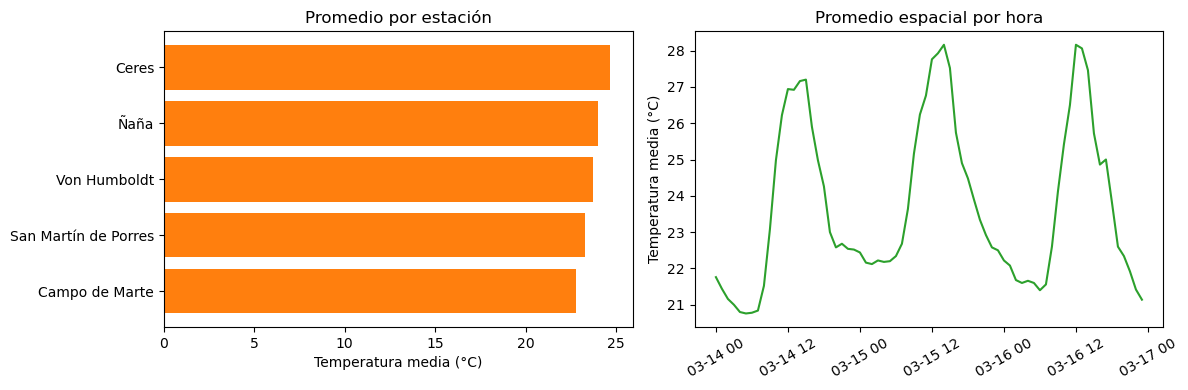

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

promedio_estacion = ds["temperatura"].mean(dim="tiempo").to_pandas().sort_values()
axes[0].barh(promedio_estacion.index, promedio_estacion.values, color="tab:orange")
axes[0].set_xlabel("Temperatura media (°C)")
axes[0].set_title("Promedio por estación")

promedio_hora = ds["temperatura"].mean(dim="estacion").to_pandas()
axes[1].plot(promedio_hora.index, promedio_hora.values, color="tab:green")
axes[1].set_ylabel("Temperatura media (°C)")
axes[1].set_title("Promedio espacial por hora")
axes[1].tick_params(axis="x", rotation=30)

fig.tight_layout()
plt.show()

## Ejercicio 4 — Serie temporal con Pandas (45 min)

**4a.** `resample("1D")` y `resample("1ME")` sobre la serie horaria de
Campo de Marte (marzo completo), graficadas juntas.

In [11]:
serie = leer_senamhi("112181_2025_03.csv")   # Campo de Marte, marzo completo

diaria = serie.resample("1D").mean()
maximos_mensuales = serie.resample("1ME").max()

print("Promedios diarios (primeros 5 días):")
print(diaria.head())
print()
print("Máximo del mes (marzo completo: un solo valor):")
print(maximos_mensuales)

Promedios diarios (primeros 5 días):
2025-03-01    24.562500
2025-03-02    25.812500
2025-03-03    25.287500
2025-03-04    22.929167
2025-03-05    23.208333
Freq: D, Name: Temperatura (°C), dtype: float64

Máximo del mes (marzo completo: un solo valor):
2025-03-31    30.5
Freq: ME, Name: Temperatura (°C), dtype: float64


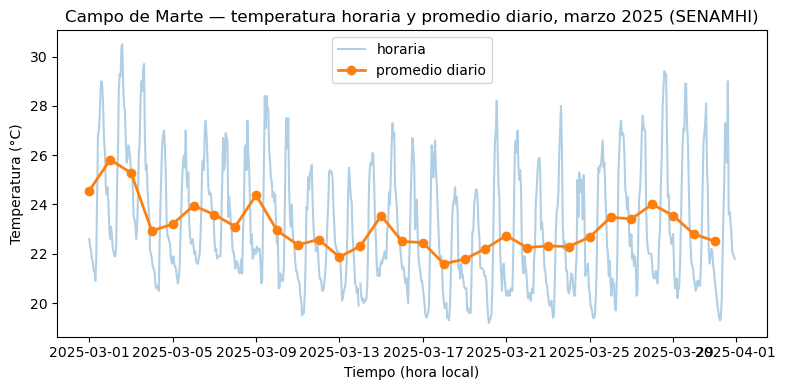

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(serie.index, serie.values, alpha=0.35, label="horaria")
ax.plot(diaria.index, diaria.values, marker="o", linewidth=2, label="promedio diario")
ax.set_xlabel("Tiempo (hora local)")
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Campo de Marte — temperatura horaria y promedio diario, marzo 2025 (SENAMHI)")
ax.legend()
fig.tight_layout()
plt.show()

**4b. Refuerzo — construir el `DatetimeIndex` desde cero.** Hasta ahora
usamos `leer_senamhi()` sin mirar por dentro. Ahora lo hacemos a mano con
el archivo de Ñaña. Así suelen llegar los datos reales: la fecha viene como
**texto**, aquí repartida en 4 columnas (`Año`, `Mes`, `Día`, `Hora`), y
donde no hay dato dice `S/D`. Hay que convertir las dos cosas.

In [13]:
# Leemos el archivo "crudo": todas las columnas como texto (dtype=str)
df_crudo = pd.read_csv(CARPETA + "111290_2025_03.csv", sep=";", dtype=str)   # Ñaña

print("Tipo de dato de 'Día' y 'Hora' ANTES de convertir:", df_crudo["Día"].dtype, df_crudo["Hora"].dtype)
df_crudo.head()

Tipo de dato de 'Día' y 'Hora' ANTES de convertir: str str


,Año,Mes,Día,Hora,Temperatura (°C),Precipitación (mm),Humedad (%),Dir. Viento (°),Vel. Viento (m/s)
0,2025,03,01,00:00,23.1,0.0,70,107,0.0
1,2025,03,01,01:00,22.6,0.0,72,92,0.0
2,2025,03,01,02:00,22.7,0.0,73,212,0.0
3,2025,03,01,03:00,22.8,0.0,73,104,0.0
4,2025,03,01,04:00,22.8,0.0,74,78,0.0


In [14]:
# 1) Juntar las 4 columnas en un texto "2025-03-01 00:00" y convertirlo a fecha.
#    set_index() lo vuelve el DatetimeIndex: recién ahí resample() funciona
df_crudo["fecha_hora"] = pd.to_datetime(
    df_crudo["Año"] + "-" + df_crudo["Mes"] + "-" + df_crudo["Día"] + " " + df_crudo["Hora"]
)
df_crudo = df_crudo.set_index("fecha_hora")
print("Tipo de dato del índice DESPUÉS de convertir:", type(df_crudo.index).__name__)

# 2) Convertir la temperatura a número: "S/D" no es un número -> NaN (sin dato)
df_crudo["temperatura"] = pd.to_numeric(df_crudo["Temperatura (°C)"], errors="coerce")
print("Horas con S/D convertidas a NaN:", df_crudo["temperatura"].isna().sum())

serie_manual = df_crudo["temperatura"]
semanal_max = serie_manual.resample("7D").max()
semanal_min = serie_manual.resample("7D").min()

print()
print("Máximos cada 7 días:")
print(semanal_max)

Tipo de dato del índice DESPUÉS de convertir: DatetimeIndex
Horas con S/D convertidas a NaN: 2

Máximos cada 7 días:
fecha_hora
2025-03-01    29.5
2025-03-08    30.3
2025-03-15    29.1
2025-03-22    28.5
2025-03-29    28.5
Freq: 7D, Name: temperatura, dtype: float64


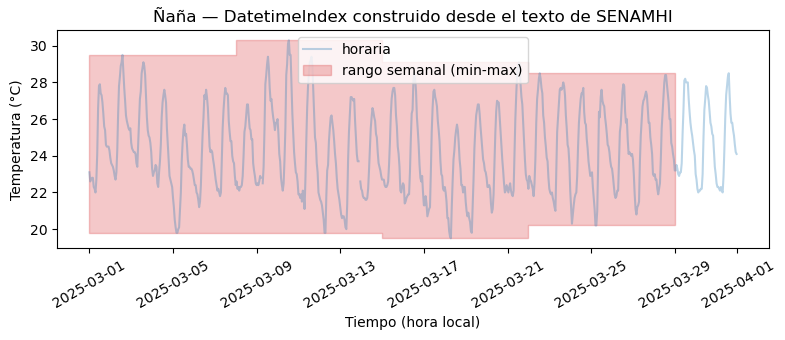

In [15]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(serie_manual.index, serie_manual.values, alpha=0.3, label="horaria")
ax.fill_between(semanal_max.index, semanal_min.values, semanal_max.values,
                 step="post", alpha=0.25, color="tab:red", label="rango semanal (min-max)")
ax.set_xlabel("Tiempo (hora local)"); ax.set_ylabel("Temperatura (°C)")
ax.set_title("Ñaña — DatetimeIndex construido desde el texto de SENAMHI")
ax.tick_params(axis="x", rotation=30)
ax.legend()
fig.tight_layout()
plt.show()

## Cierre

Entregable del día: este notebook resuelto. La integración final de las
cuatro librerías en un solo flujo se hace en
[`04_entregable_integrador.ipynb`](04_entregable_integrador.ipynb).